# 32 · 计算图、链式法则与梯度

公用基础路径：31 → 32 → 33 → 34，再进入搜索、广告或推荐。

**范围：小数组构造机制实验，CPU执行，无真实日志、无正式模型训练或业务收益主张。**

每节先预测 → 只改一个变量 → 运行 → 解释。首次从头执行，后续修改时重跑相关下游格。

## 构造标量计算图

z=wx+b，L=(z-y)^2。先手算 dL/dw=2(z-y)x。所有数值为 float64。

In [1]:
import torch
import matplotlib.pyplot as plt
x, y = 2., 1.
w = torch.tensor(0.5, dtype=torch.float64, requires_grad=True)
b = torch.tensor(0.2, dtype=torch.float64, requires_grad=True)
z = w*x+b
loss = (z-y)**2
loss.backward()
assert torch.allclose(w.grad, 2*(z.detach()-y)*x)
print('z, loss, dw, db:', z.item(), loss.item(), w.grad.item(), b.grad.item())

z, loss, dw, db: 1.2 0.03999999999999998 0.7999999999999998 0.3999999999999999


## 用有限差分核对

只改变差分步长；中心差分近似梯度，过小步长可能产生消减误差。

[(0.01, 0.8000000000000007), (1e-05, 0.7999999999962897), (1e-08, 0.7999999995789153), (1e-12, 0.7999816087345124)]


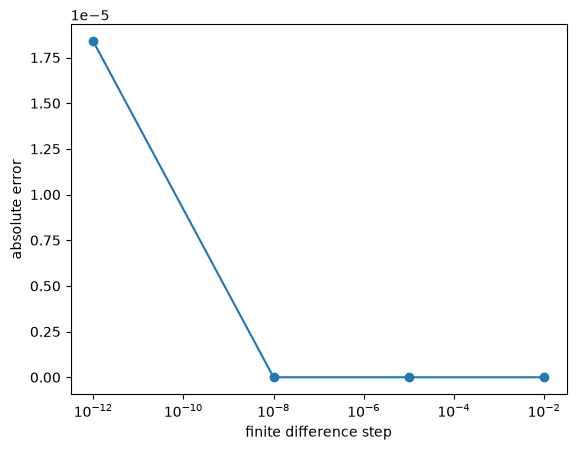

In [2]:
def objective(value):
    return (value*x+b.detach().item()-y)**2
steps = [1e-2, 1e-5, 1e-8, 1e-12]
estimates = [(objective(w.item()+h)-objective(w.item()-h))/(2*h) for h in steps]
assert abs(estimates[1]-w.grad.item()) < 1e-8
print(list(zip(steps, estimates)))
plt.semilogx(steps, [abs(v-w.grad.item()) for v in estimates], 'o-')
plt.xlabel('finite difference step'); plt.ylabel('absolute error'); plt.show()

## 梯度累加

再次构建相同图再 backward；预测梯度是否自动清零。

In [3]:
first = w.grad.clone()
((w*x+b-y)**2).backward()
assert torch.allclose(w.grad, 2*first)
print('累加后的梯度:', w.grad.item())
w.grad = None
b.grad = None
((w*x+b-y)**2).backward()
assert torch.allclose(w.grad, first)

累加后的梯度: 1.5999999999999996


## 只改学习率

从同一 w 出发，固定当前 b；下降方向不保证任意步长都下降。

In [4]:
rates = [0.05, 1.0]
new_losses = [objective(w.item()-lr*w.grad.item()) for lr in rates]
assert new_losses[0] < loss.item() < new_losses[1]
print('原损失:', loss.item(), '更新后:', dict(zip(rates, new_losses)))

原损失: 0.03999999999999998 更新后: {0.05: 0.014400000000000026, 1.0: 1.959999999999999}


## 解释练习

解释：梯度是局部斜率还是最终参数？为什么每个训练批次通常要清梯度？大步长失败能否说明链式法则错误？

在下格记录预测、实际结果、差异原因与适用边界；保留失败结果。

In [5]:
reflection = {'预测': '', '结果': '', '解释与边界': ''}
reflection

{'预测': '', '结果': '', '解释与边界': ''}